# 03. Аномалия 2014 года в train

В `02_profiling` замечено: в 2014 г. число строк и число товаров в день меняются ступеньками
на границах месяцев, а падение 2014-04-01 совпадает с концом NULL в `onpromotion`.
Здесь проверяем три гипотезы:

| | Гипотеза | Что она предсказывает |
|---|---|---|
| **H1** | Неполная запись: в отдельные месяцы записан не весь ассортимент | ступеньки синхронны во всех магазинах, число чеков не меняется, пропадают и «ходовые» товары |
| **H2** | Реальная смена ассортимента (в т.ч. сезонная) | ступеньки повторяются в те же месяцы других лет, пропавшие товары не возвращаются через месяц, магазины меняются по-разному |
| **H3** | Артефакт сборки/прореживания датасета | синхронные ступеньки ровно по границам месяцев; пропадают в основном редкие/малопродаваемые товары (отбор по объёму) |

## 0. Подготовка

Ячейка подготовки скопирована из `02_profiling.ipynb`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRONZE = ROOT / "data" / "bronze"

TABLES = ["train", "test", "stores", "items", "transactions", "oil", "holidays_events"]
DATED = {"train", "test", "transactions", "oil", "holidays_events"}


def parquet_source(name: str) -> str:
    """Файл <name>.parquet или каталог <name>/ с parquet-частями."""
    f = BRONZE / f"{name}.parquet"
    if f.is_file():
        return f.as_posix()
    d = BRONZE / name
    if d.is_dir():
        return (d / "**" / "*.parquet").as_posix()
    raise FileNotFoundError(f"Не найден parquet для таблицы {name!r} в {BRONZE}")


con = duckdb.connect()
con.execute("SET memory_limit = '6GB'")  # подстрой под свою машину
con.execute("SET preserve_insertion_order = false")

for t in TABLES:
    select = "SELECT * REPLACE (CAST(date AS DATE) AS date)" if t in DATED else "SELECT *"
    con.execute(f"CREATE OR REPLACE VIEW {t} AS {select} FROM read_parquet('{parquet_source(t)}')")


def q(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()


def scalar(sql: str) -> int:
    """Первое значение первой строки (у DuckDBPyRelation в duckdb 2.x нет fetchone)."""
    return int(con.sql(sql).fetchall()[0][0])

In [2]:
import numpy as np

# Дневной ряд по всему train: строки, магазины, товары, продажи, заполненность onpromotion
con.execute("""
    CREATE OR REPLACE TABLE daily AS
    SELECT date,
           date_trunc('month', date)::DATE AS month,
           count(*)                        AS n_rows,
           count(DISTINCT store_nbr)       AS n_stores,
           count(DISTINCT item_nbr)        AS n_items,
           sum(unit_sales)                 AS unit_sales,
           count(onpromotion)              AS n_promo_notnull
    FROM train
    GROUP BY date
""")

# Присутствие товара / пары (магазин, товар) в месяце — основа для проверок 2 и 6
con.execute("""
    CREATE OR REPLACE TABLE item_month AS
    SELECT DISTINCT date_trunc('month', date)::DATE AS month, item_nbr FROM train
""")
con.execute("""
    CREATE OR REPLACE TABLE pair_month AS
    SELECT DISTINCT date_trunc('month', date)::DATE AS month, store_nbr, item_nbr FROM train
""")
print(scalar("SELECT count(*) FROM daily"), "дней;",
      scalar("SELECT count(*) FROM item_month"), "строк товар×месяц;",
      scalar("SELECT count(*) FROM pair_month"), "строк пара×месяц")

1684 дней; 158798 строк товар×месяц; 5813304 строк пара×месяц


## 1. Дневной ряд и помесячные ступеньки

**Ожидания.** При любой гипотезе ступеньки видны в n_items и n_rows. Здесь фиксируем, *где* они:
если изменение происходит ровно 1-го числа и держится весь месяц — граница месяца работает
как единица сборки/выгрузки (H1/H3); плавное изменение внутри месяца больше похоже на H2.

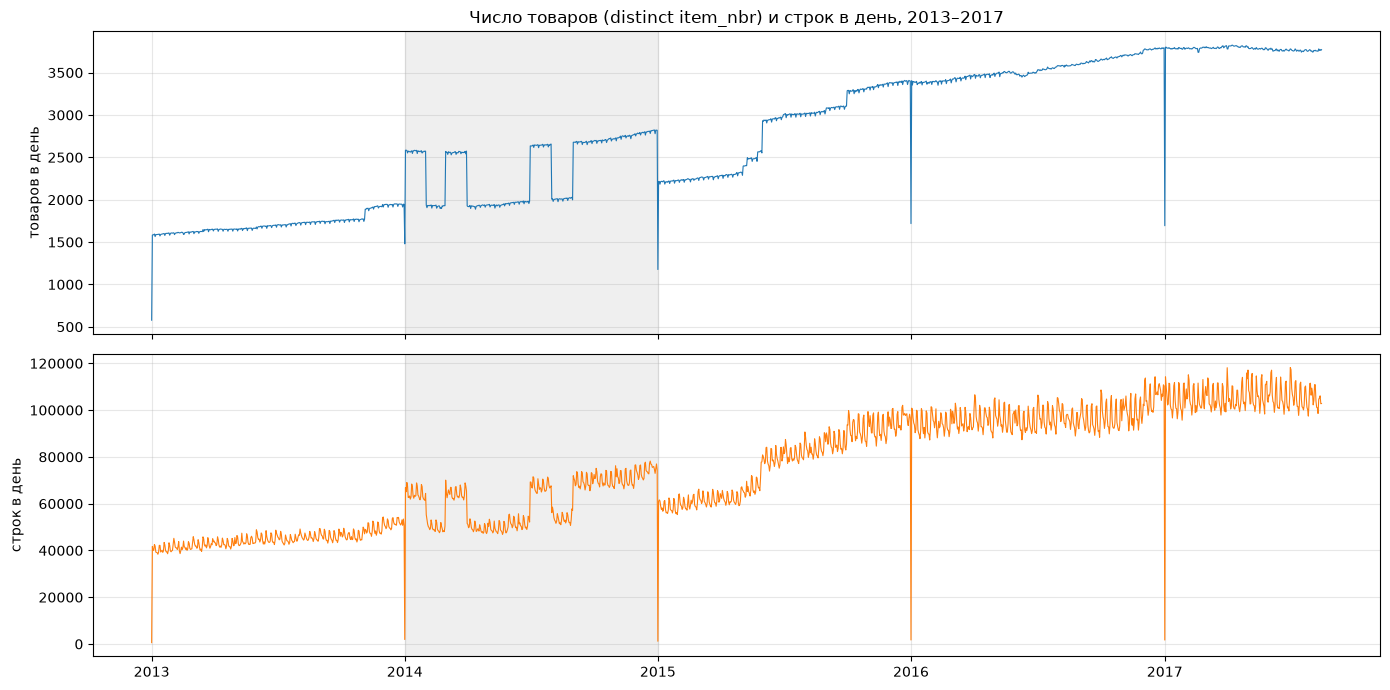

In [3]:
daily = q("SELECT * FROM daily ORDER BY date")

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(daily["date"], daily["n_items"], lw=0.8)
axes[0].set_ylabel("товаров в день")
axes[0].set_title("Число товаров (distinct item_nbr) и строк в день, 2013–2017")
axes[1].plot(daily["date"], daily["n_rows"], lw=0.8, color="tab:orange")
axes[1].set_ylabel("строк в день")
for ax in axes:
    ax.axvspan(pd.Timestamp("2014-01-01"), pd.Timestamp("2015-01-01"), color="grey", alpha=0.12)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
monthly = q("""
    SELECT month,
           median(n_items)  AS med_items,
           median(n_rows)   AS med_rows,
           median(n_stores) AS med_stores,
           count(*)         AS n_days
    FROM daily GROUP BY month ORDER BY month
""")
monthly["d_items_%"] = (monthly["med_items"].pct_change() * 100).round(1)
monthly["d_rows_%"] = (monthly["med_rows"].pct_change() * 100).round(1)
monthly["step"] = monthly["d_items_%"].abs() > 10
monthly["month"] = monthly["month"].dt.strftime("%Y-%m")
monthly

,month,med_items,med_rows,med_stores,n_days,d_items_%,d_rows_%,step
0,2013-01,1593.0,39863.0,46.0,31,NaN,NaN,False
1,2013-02,1611.5,41112.5,46.0,28,1.2,3.1,False
2,2013-03,1625.0,42372.0,46.0,31,0.8,3.1,False
3,2013-04,1650.5,42308.5,46.0,30,1.6,-0.1,False
4,2013-05,1659.0,43233.0,47.0,31,0.5,2.2,False
5,2013-06,1689.0,44376.5,47.0,30,1.8,2.6,False
6,2013-07,1705.0,44162.0,46.0,31,0.9,-0.5,False
7,2013-08,1734.0,45413.0,47.0,31,1.7,2.8,False
8,2013-09,1746.0,45257.0,47.0,30,0.7,-0.3,False
9,2013-10,1764.0,45523.0,47.0,31,1.0,0.6,False


In [5]:
print("Месяцы, где |изменение медианы n_items| > 10 %:")
monthly.loc[monthly["step"], ["month", "med_items", "med_rows", "d_items_%", "d_rows_%"]]

Месяцы, где |изменение медианы n_items| > 10 %:


,month,med_items,med_rows,d_items_%,d_rows_%
12,2014-01,2573.0,63290.0,32.4,23.6
13,2014-02,1929.0,49341.5,-25.0,-22.0
14,2014-03,2559.0,63887.0,32.7,29.5
15,2014-04,1927.0,49085.5,-24.7,-23.2
18,2014-07,2644.0,66969.0,34.1,31.4
19,2014-08,2010.0,52994.0,-24.0,-20.9
20,2014-09,2682.0,68534.0,33.4,29.3
24,2015-01,2217.0,57478.0,-20.8,-22.5
29,2015-06,2947.0,78293.5,18.6,18.8


In [6]:
# Где именно происходят скачки: дни, когда n_items изменилось > 10 % к предыдущему дню
daily["d_items_%"] = (daily["n_items"].pct_change() * 100).round(1)
jumps = daily.loc[daily["d_items_%"].abs() > 10,
                  ["date", "n_items", "d_items_%", "n_rows", "n_promo_notnull"]]
jumps

,date,n_items,d_items_%,n_rows,n_promo_notnull
1,2013-01-02,1583,173.9,41676,0
364,2014-01-01,1479,-24.0,1911,0
365,2014-01-02,2584,74.7,66819,0
395,2014-02-01,1936,-24.8,55290,0
423,2014-03-01,2570,33.2,70051,0
454,2014-04-01,1927,-25.1,51537,51537
545,2014-07-01,2635,33.0,69290,69290
576,2014-08-01,2006,-24.5,56164,56164
607,2014-09-01,2678,34.0,71954,71954
728,2015-01-01,1176,-58.3,1176,1176


## 2. «Дырявые» товары: есть в m−1 и m+1, нет в m

Для месяца m берём товары, присутствующие (в любом магазине) и в m−1, и в m+1, и считаем,
сколько из них полностью отсутствуют в m. То же для пар (магазин, товар).

**Ожидания.**
* H1/H3: в «провальных» месяцах доля дыр резко выше фона — товары временно «выключены»
  целиком, а через месяц возвращаются.
* H2 (реальный вывод/ввод товаров): выведенный товар через месяц не возвращается,
  поэтому доля дыр должна быть близка к фону других лет.
* Фон — 2015–2017: естественная прерывистость редких товаров.

In [7]:
def holes(table: str, keys: list[str]) -> pd.DataFrame:
    """Для каждого месяца m: сколько ключей есть в m-1 и m+1 и сколько из них нет в m."""
    on_c = " AND ".join(f"c.{k} = a.{k}" for k in keys)
    on_b = " AND ".join(f"b.{k} = a.{k}" for k in keys)
    return q(f"""
        WITH months AS (SELECT DISTINCT month FROM {table})
        SELECT m.month,
               count(*)                                AS n_both_neighbours,
               count(*) FILTER (WHERE b.month IS NULL) AS n_holes
        FROM months m
        JOIN {table} a ON a.month = m.month - INTERVAL 1 MONTH
        JOIN {table} c ON c.month = m.month + INTERVAL 1 MONTH AND {on_c}
        LEFT JOIN {table} b ON b.month = m.month AND {on_b}
        GROUP BY m.month ORDER BY m.month
    """)


h_item = holes("item_month", ["item_nbr"])
h_pair = holes("pair_month", ["store_nbr", "item_nbr"])
h = h_item.merge(h_pair, on="month", suffixes=("_item", "_pair"))
h["holes_item_%"] = (h["n_holes_item"] / h["n_both_neighbours_item"] * 100).round(2)
h["holes_pair_%"] = (h["n_holes_pair"] / h["n_both_neighbours_pair"] * 100).round(2)
h["month"] = h["month"].dt.strftime("%Y-%m")
h

,month,n_both_neighbours_item,n_holes_item,n_both_neighbours_pair,n_holes_pair,holes_item_%,holes_pair_%
0,2013-02,1615,0,52704,275,0.00,0.52
1,2013-03,1628,0,53052,242,0.00,0.46
2,2013-04,1657,2,54653,422,0.12,0.77
3,2013-05,1663,3,55082,317,0.18,0.58
4,2013-06,1673,0,56768,308,0.00,0.54
5,2013-07,1705,0,57792,384,0.00,0.66
6,2013-08,1727,0,58286,364,0.00,0.62
7,2013-09,1750,1,58755,416,0.06,0.71
8,2013-10,1772,1,59430,436,0.06,0.73
9,2013-11,1789,0,59962,361,0.00,0.60


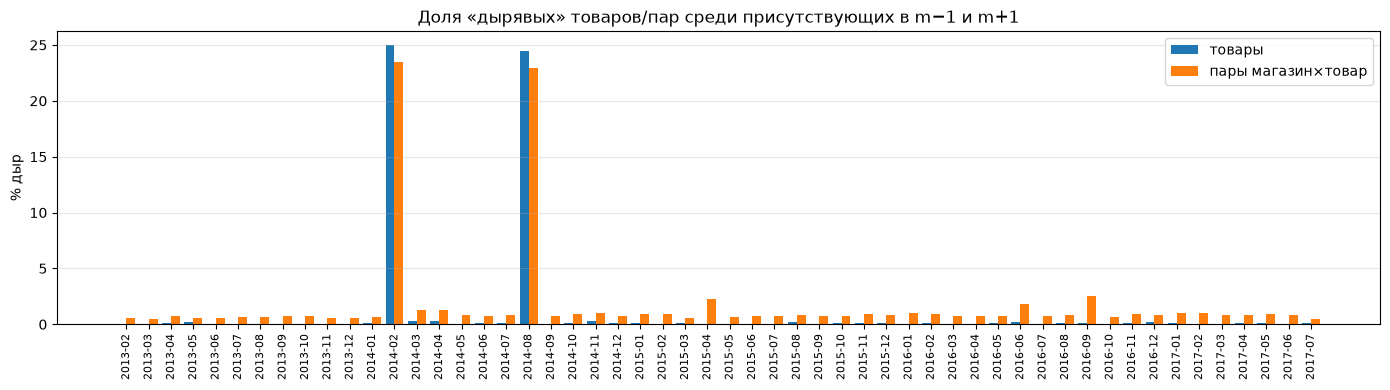

In [8]:
fig, ax = plt.subplots(figsize=(14, 4))
x = np.arange(len(h))
ax.bar(x - 0.2, h["holes_item_%"], width=0.4, label="товары")
ax.bar(x + 0.2, h["holes_pair_%"], width=0.4, label="пары магазин×товар")
ax.set_xticks(x, h["month"], rotation=90, fontsize=8)
ax.set_ylabel("% дыр")
ax.set_title("Доля «дырявых» товаров/пар среди присутствующих в m−1 и m+1")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Сравнение 2014 с фоном 2015–2017
h["year"] = h["month"].str[:4]
h.groupby("year")[["holes_item_%", "holes_pair_%"]].agg(["median", "max"]).round(2)

holes_item_%        holes_pair_%       
           median    max       median    max
year                                        
2013         0.00   0.18         0.60   0.77
2014         0.13  25.00         0.90  23.45
2015         0.08   0.20         0.80   2.27
2016         0.08   0.18         0.84   2.54
2017         0.08   0.13         0.87   0.99

## 3. Сезонность: повторяются ли ступеньки в другие годы?

**Ожидания.** H2 (сезонный ассортимент): рисунок «вверх/вниз» по месяцам повторяется в
2013, 2015, 2016. H1/H3: рисунок уникален для 2014 г.

In [10]:
mm = q("SELECT month, median(n_items) AS med_items FROM daily GROUP BY month")
mm["year"] = mm["month"].dt.year
mm["m"] = mm["month"].dt.month
pivot = mm.pivot(index="year", columns="m", values="med_items")
pivot_pct = (pivot.pct_change(axis=1) * 100).round(1)
display(pivot)
print("Изменение к предыдущему месяцу того же года, %:")
display(pivot_pct)

m,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2013,1593.0,1611.5,1625.0,1650.5,1659.0,1689.0,1705.0,1734.0,1746.0,1764.0,1903.0,1944.0
2014,2573.0,1929.0,2559.0,1927.0,1938.0,1971.5,2644.0,2010.0,2682.0,2700.0,2749.0,2797.5
2015,2217.0,2239.0,2268.0,2295.5,2484.0,2947.0,3010.0,3023.0,3091.0,3293.0,3341.5,3386.5
2016,3386.0,3401.0,3437.0,3475.0,3498.0,3478.0,3545.0,3584.0,3627.0,3672.0,3711.5,3779.0
2017,3786.0,3788.5,3794.0,3813.0,3783.0,3765.5,3760.0,3759.0,NaN,NaN,NaN,NaN


Изменение к предыдущему месяцу того же года, %:


m,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2013,NaN,1.2,0.8,1.6,0.5,1.8,0.9,1.7,0.7,1.0,7.9,2.2
2014,NaN,-25.0,32.7,-24.7,0.6,1.7,34.1,-24.0,33.4,0.7,1.8,1.8
2015,NaN,1.0,1.3,1.2,8.2,18.6,2.1,0.4,2.2,6.5,1.5,1.3
2016,NaN,0.4,1.1,1.1,0.7,-0.6,1.9,1.1,1.2,1.2,1.1,1.8
2017,NaN,0.1,0.1,0.5,-0.8,-0.5,-0.1,-0.0,NaN,NaN,NaN,NaN


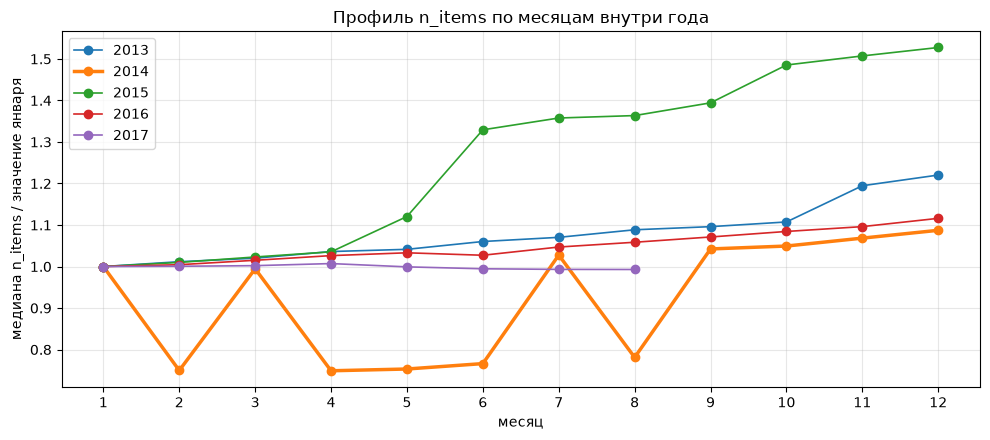

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for year, row in pivot.iterrows():
    row = row.dropna()
    ax.plot(row.index, row.values / row.iloc[0], marker="o", label=str(year),
            lw=2.5 if year == 2014 else 1.2)
ax.set_xticks(range(1, 13))
ax.set_xlabel("месяц")
ax.set_ylabel("медиана n_items / значение января")
ax.set_title("Профиль n_items по месяцам внутри года")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. По магазинам: изменение числа товаров на границах месяцев

Для пар соседних дат считаем % изменения числа товаров в каждом магазине (только магазины,
торговавшие в оба дня).

**Ожидания.** Почти все магазины в одну сторону и на похожий процент — изменение источника
данных (H1/H3). Часть магазинов не меняется или меняется в разные стороны — локальные решения
по ассортименту (H2).

Кроме пяти заданных границ добавлены 2013-12-31/2014-01-02, 2014-01-31/2014-02-01,
2014-12-31/2015-01-02 и 2015-05-31/2015-06-01 — там тоже ступеньки (см. п. 1). Для новогодних
границ берётся 2 января: 1 января работают только 1–2 магазина, это сравнение бессмысленно.
Две границы 2016 г. — контроль.

In [12]:
BOUNDARIES = [
    ("2013-12-31", "2014-01-02"),
    ("2014-01-31", "2014-02-01"),
    ("2014-02-28", "2014-03-01"),
    ("2014-03-31", "2014-04-01"),
    ("2014-06-30", "2014-07-01"),
    ("2014-07-31", "2014-08-01"),
    ("2014-08-31", "2014-09-01"),
    ("2014-12-31", "2015-01-02"),
    ("2015-05-31", "2015-06-01"),
]
CONTROL = [("2016-03-31", "2016-04-01"), ("2016-07-31", "2016-08-01")]  # обычные границы


def store_change(d0: str, d1: str) -> dict:
    s = q(f"""
        SELECT store_nbr,
               count(DISTINCT item_nbr) FILTER (WHERE date = DATE '{d0}') AS n0,
               count(DISTINCT item_nbr) FILTER (WHERE date = DATE '{d1}') AS n1
        FROM train WHERE date IN (DATE '{d0}', DATE '{d1}')
        GROUP BY store_nbr
    """)
    s = s[(s["n0"] > 0) & (s["n1"] > 0)]
    pct = (s["n1"] / s["n0"] - 1) * 100
    n0 = scalar(f"SELECT n_items FROM daily WHERE date = DATE '{d0}'")
    n1 = scalar(f"SELECT n_items FROM daily WHERE date = DATE '{d1}'")
    total = (n1 / n0 - 1) * 100
    return {
        "граница": f"{d0} → {d1}",
        "Δ всего, %": round(total, 1),
        "магазинов": len(s),
        "в ту же сторону": int((np.sign(pct) == np.sign(total)).sum()),
        "|Δ| > 10 %": int((pct.abs() > 10).sum()),
        "медиана, %": round(pct.median(), 1),
        "min, %": round(pct.min(), 1),
        "max, %": round(pct.max(), 1),
    }


by_store = pd.DataFrame([store_change(*b) for b in BOUNDARIES + CONTROL])
by_store["контроль"] = by_store["граница"].str.startswith("2016")
by_store

,граница,"Δ всего, %",магазинов,в ту же сторону,|Δ| > 10 %,"медиана, %","min, %","max, %",контроль
0,2013-12-31 → 2014-01-02,32.9,47,46,46,32.5,-3.1,65.8,False
1,2014-01-31 → 2014-02-01,-24.8,47,46,32,-13.9,-22.9,9.4,False
2,2014-02-28 → 2014-03-01,33.2,47,47,47,38.8,25.5,63.8,False
3,2014-03-31 → 2014-04-01,-25.1,47,47,46,-21.4,-26.9,-9.3,False
4,2014-06-30 → 2014-07-01,33.0,47,47,47,32.7,23.9,45.9,False
5,2014-07-31 → 2014-08-01,-24.5,48,48,46,-17.5,-21.6,-2.6,False
6,2014-08-31 → 2014-09-01,34.0,47,46,46,25.6,-1.4,83.7,False
7,2014-12-31 → 2015-01-02,-21.5,48,47,44,-17.8,-35.4,1.2,False
8,2015-05-31 → 2015-06-01,14.9,50,35,6,3.2,-14.4,51.9,False
9,2016-03-31 → 2016-04-01,0.2,53,51,18,8.2,-2.6,31.6,True


## 5. Транзакции против строк вокруг границ (±10 дней)

`transactions` — число чеков по магазину, собирается отдельно от train.

**Ожидания.** Чеки стабильны, а n_rows, n_items и unit_sales падают ступенькой —
меняется *запись* продаж (H1/H3), а не спрос. Чеки тоже ступенькой — реальное событие.

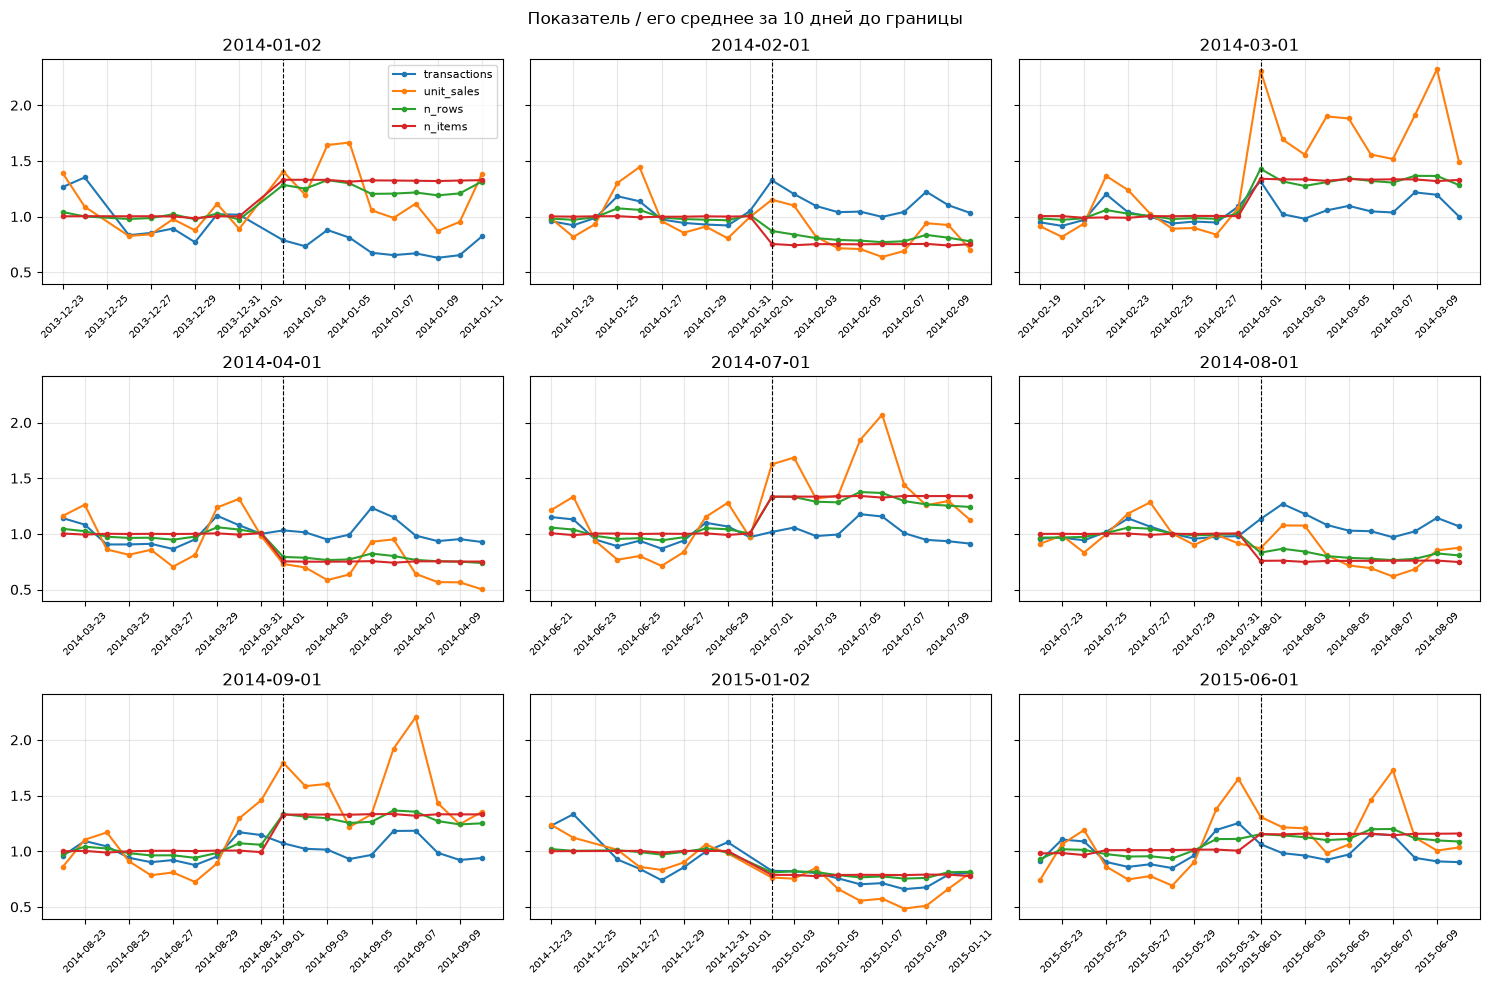

Среднее за 10 дней после границы к среднему за 10 дней до, %


,граница,transactions Δ%,unit_sales Δ%,n_rows Δ%,n_items Δ%
0,2014-01-02,-26.9,22.7,25.0,32.4
1,2014-02-01,11.0,-16.1,-19.4,-25.0
2,2014-03-01,9.7,81.4,33.1,33.1
3,2014-04-01,1.7,-32.0,-22.5,-24.9
4,2014-07-01,1.8,50.0,30.3,33.6
5,2014-08-01,9.2,-17.3,-19.3,-24.4
6,2014-09-01,2.1,56.9,29.4,32.9
7,2015-01-02,-24.5,-33.8,-21.0,-21.5
8,2015-06-01,-0.5,21.2,13.3,15.5


In [13]:
def window(d1: str, days: int = 10) -> pd.DataFrame:
    return q(f"""
        WITH tr AS (
            SELECT date, sum(transactions) AS transactions FROM transactions
            GROUP BY date
        )
        SELECT d.date, tr.transactions, d.unit_sales, d.n_rows, d.n_items
        FROM daily d LEFT JOIN tr USING (date)
        WHERE d.date >= DATE '{d1}' - INTERVAL {days} DAY
          AND d.date <  DATE '{d1}' + INTERVAL {days} DAY
          AND strftime(d.date, '%m-%d') <> '01-01'  -- 1 января почти все магазины закрыты
        ORDER BY d.date
    """)


cols = ["transactions", "unit_sales", "n_rows", "n_items"]
summary = []
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharey=True)
for ax, (_, d1) in zip(axes.flat, BOUNDARIES):
    w = window(d1)
    before = w[w["date"] < pd.Timestamp(d1)]
    after = w[w["date"] >= pd.Timestamp(d1)]
    rec = {"граница": d1}
    for c in cols:
        rec[f"{c} Δ%"] = round((after[c].mean() / before[c].mean() - 1) * 100, 1)
        ax.plot(w["date"], w[c] / before[c].mean(), marker=".", label=c)
    summary.append(rec)
    ax.axvline(pd.Timestamp(d1), color="k", ls="--", lw=0.8)
    ax.set_title(d1)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.grid(alpha=0.3)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Показатель / его среднее за 10 дней до границы")
plt.tight_layout()
plt.show()

print("Среднее за 10 дней после границы к среднему за 10 дней до, %")
tx_summary = pd.DataFrame(summary)
tx_summary

In [14]:
# Детально: ±10 дней вокруг 2014-04-01
window("2014-04-01")

,date,transactions,unit_sales,n_rows,n_items
0,2014-03-22,93889.0,771704.9340,67983,2567
1,2014-03-23,89071.0,838814.6360,66562,2542
2,2014-03-24,74406.0,571762.0450,63337,2561
3,2014-03-25,74454.0,539861.6184,62650,2556
4,2014-03-26,74887.0,569680.5432,62774,2560
5,2014-03-27,71079.0,468581.3983,61580,2555
6,2014-03-28,78180.0,538905.7822,63426,2560
7,2014-03-29,95635.0,822333.1440,68879,2571
8,2014-03-30,88582.0,873958.8400,67532,2541
9,2014-03-31,82265.0,651800.5090,65381,2574


## 6. Профиль пропавших товаров: март → апрель 2014

* `vanished` — товар есть в марте 2014, полностью отсутствует в апреле и снова есть в мае;
* `stayed` — есть и в марте, и в апреле;
* `gone` — есть в марте, нет ни в апреле, ни в мае (для справки).

Характеристики считаются по марту: доля дней с продажами (хотя бы в одном магазине),
средние unit_sales в день, число магазинов, семейства.

**Ожидания.**
* Пропадают товары, продававшиеся почти каждый день, — реального нулевого спроса в апреле
  быть не могло: недозапись (H1/H3).
* Пропадают в основном редкие товары с низкими продажами — прореживание по объёму (H3)
  или естественная прерывистость.

In [15]:
def vanished_profile(m_prev: str, m_gap: str, m_next: str) -> pd.DataFrame:
    """Товары месяца m_prev с группой (stayed / vanished / gone) и статистикой за m_prev."""
    n_days = scalar(f"SELECT count(*) FROM daily WHERE month = DATE '{m_prev}'")
    return q(f"""
        WITH grp AS (
            SELECT p.item_nbr,
                   CASE WHEN g.item_nbr IS NOT NULL THEN 'stayed'
                        WHEN n.item_nbr IS NOT NULL THEN 'vanished'
                        ELSE 'gone' END AS grp
            FROM item_month p
            LEFT JOIN item_month g ON g.item_nbr = p.item_nbr AND g.month = DATE '{m_gap}'
            LEFT JOIN item_month n ON n.item_nbr = p.item_nbr AND n.month = DATE '{m_next}'
            WHERE p.month = DATE '{m_prev}'
        ),
        stats AS (
            SELECT item_nbr,
                   count(DISTINCT date)           AS days_sold,
                   sum(unit_sales) / {n_days}     AS sales_per_day,
                   count(DISTINCT store_nbr)      AS n_stores
            FROM train
            WHERE date_trunc('month', date) = DATE '{m_prev}'
            GROUP BY item_nbr
        )
        SELECT g.item_nbr, g.grp, s.days_sold, s.days_sold / {n_days} AS share_days,
               s.sales_per_day, s.n_stores, i.family, i.perishable
        FROM grp g JOIN stats s USING (item_nbr) JOIN items i USING (item_nbr)
    """)


def summarize(p: pd.DataFrame) -> pd.DataFrame:
    return p.groupby("grp").agg(
        n_items=("item_nbr", "size"),
        share_days_median=("share_days", "median"),
        share_days_mean=("share_days", "mean"),
        sold_every_day=("share_days", lambda s: int((s == 1).sum())),
        sold_every_day_pct=("share_days", lambda s: (s == 1).mean() * 100),
        sales_per_day_median=("sales_per_day", "median"),
        sales_per_day_mean=("sales_per_day", "mean"),
        n_stores_median=("n_stores", "median"),
        perishable_pct=("perishable", lambda s: s.mean() * 100),
    ).round(2)


p_apr = vanished_profile("2014-03-01", "2014-04-01", "2014-05-01")
summarize(p_apr)

,n_items,share_days_median,share_days_mean,sold_every_day,sold_every_day_pct,sales_per_day_median,sales_per_day_mean,n_stores_median,perishable_pct
grp,,,,,,,,,
gone,665,1.00,0.95,596,89.62,159.93,319.00,29.0,37.29
stayed,1967,1.00,0.98,1820,92.53,141.97,225.78,32.0,25.78
vanished,5,0.61,0.59,2,40.00,4.13,140.66,7.0,60.00


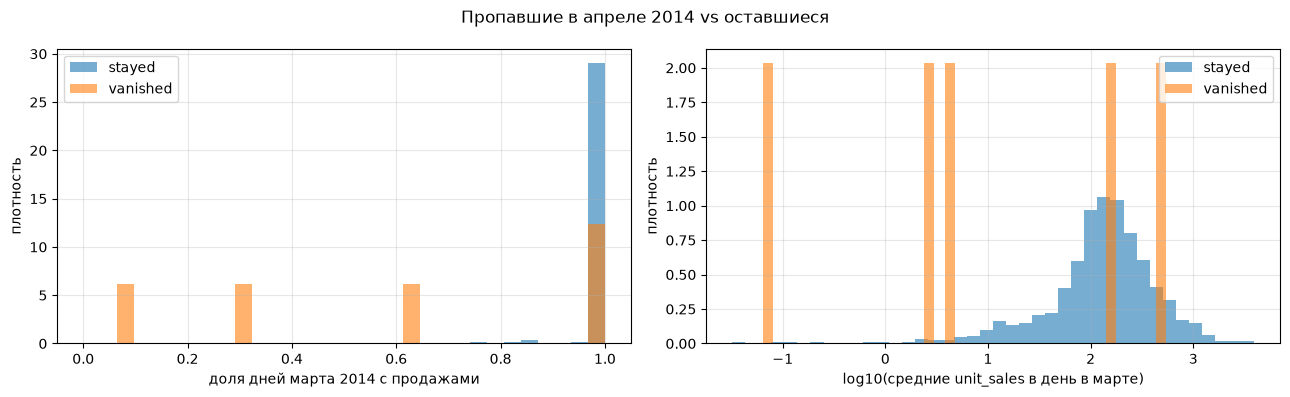

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for g in ["stayed", "vanished"]:
    sub = p_apr[p_apr["grp"] == g]
    axes[0].hist(sub["share_days"], bins=np.linspace(0, 1, 32), alpha=0.6, density=True, label=g)
    axes[1].hist(np.log10(sub["sales_per_day"].clip(lower=1e-3)), bins=40, alpha=0.6,
                 density=True, label=g)
axes[0].set_xlabel("доля дней марта 2014 с продажами")
axes[1].set_xlabel("log10(средние unit_sales в день в марте)")
for ax in axes:
    ax.set_ylabel("плотность")
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle("Пропавшие в апреле 2014 vs оставшиеся")
plt.tight_layout()
plt.show()

In [17]:
# Семейства: число и доля пропавших внутри семейства
fam = (p_apr[p_apr["grp"].isin(["stayed", "vanished"])]
       .groupby("family")["grp"].value_counts().unstack(fill_value=0))
fam["vanished_%"] = (fam["vanished"] / (fam["vanished"] + fam["stayed"]) * 100).round(1)
fam.sort_values("vanished", ascending=False).head(15)

grp,stayed,vanished,vanished_%
family,,,
BREAD/BAKERY,95,3,3.1
GROCERY I,763,2,0.3
BEAUTY,6,0,0.0
BEVERAGES,167,0,0.0
CLEANING,318,0,0.0
AUTOMOTIVE,13,0,0.0
DAIRY,156,0,0.0
DELI,71,0,0.0
EGGS,39,0,0.0


In [18]:
# Связь с объёмом: доля пропавших по децилям продаж в марте.
# Отбор по объёму дал бы монотонно убывающую зависимость.
def by_decile(p: pd.DataFrame) -> pd.DataFrame:
    pp = p[p["grp"].isin(["stayed", "vanished"])].copy()
    pp["sales_decile"] = pd.qcut(pp["sales_per_day"].rank(method="first"), 10,
                                 labels=range(1, 11))
    return pp.groupby("sales_decile", observed=True).agg(
        n=("item_nbr", "size"),
        vanished_pct=("grp", lambda s: (s == "vanished").mean() * 100),
        sales_per_day_median=("sales_per_day", "median"),
        share_days_median=("share_days", "median"),
    ).round(2)


by_decile(p_apr)

,n,vanished_pct,sales_per_day_median,share_days_median
sales_decile,,,,
1,198,1.52,11.45,1.0
2,197,0.00,45.06,1.0
3,197,0.00,78.13,1.0
4,197,0.00,102.51,1.0
5,197,0.00,127.10,1.0
6,197,0.51,158.71,1.0
7,197,0.00,197.58,1.0
8,197,0.00,255.10,1.0
9,197,0.00,374.10,1.0


### 6а. Кто на самом деле пропадает в апреле

По определению задания `vanished` (вернулись уже в мае) — всего несколько товаров. Основная
масса пропавших — группа `gone`: ≈665 товаров, которые в марте продавались **почти каждый
день и во многих магазинах**, но отсутствуют и в апреле, и в мае. Смотрим, в каких месяцах
этот блок вообще присутствует в train.

товаров в блоке: 665


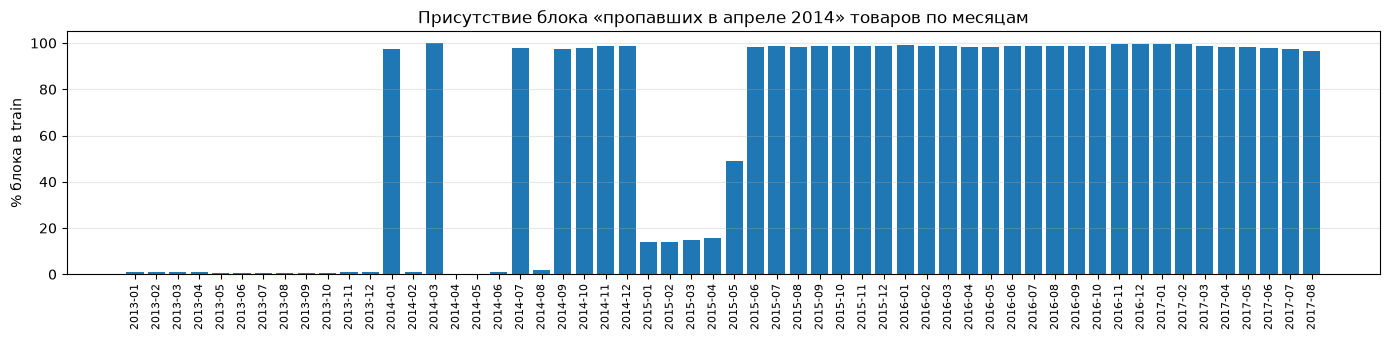

month,2013-11,2013-12,2014-01,2014-02,2014-03,2014-04,2014-05,2014-06,2014-07,2014-08,...,2014-11,2014-12,2015-01,2015-02,2015-03,2015-04,2015-05,2015-06,2015-07,2015-08
n_present,6.0,6.0,647.0,6.0,665.0,0.0,0.0,5.0,652.0,11.0,...,656.0,658.0,93.0,94.0,100.0,105.0,326.0,655.0,656.0,654.0
share_%,0.9,0.9,97.3,0.9,100.0,0.0,0.0,0.8,98.0,1.7,...,98.6,98.9,14.0,14.1,15.0,15.8,49.0,98.5,98.6,98.3


In [19]:
con.execute("""
    CREATE OR REPLACE TABLE block AS
    SELECT item_nbr FROM item_month WHERE month = DATE '2014-03-01'
    EXCEPT
    SELECT item_nbr FROM item_month WHERE month IN (DATE '2014-04-01', DATE '2014-05-01')
""")
n_block = scalar("SELECT count(*) FROM block")
cal = q("""
    SELECT m.month, count(b.item_nbr) AS n_present
    FROM (SELECT DISTINCT month FROM item_month) m
    LEFT JOIN item_month im ON im.month = m.month
    LEFT JOIN block b ON b.item_nbr = im.item_nbr
    GROUP BY m.month ORDER BY m.month
""")
cal["share_%"] = (cal["n_present"] / n_block * 100).round(1)
cal["month"] = cal["month"].dt.strftime("%Y-%m")
print("товаров в блоке:", n_block)

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(cal["month"], cal["share_%"])
ax.set_xticks(range(len(cal)), cal["month"], rotation=90, fontsize=8)
ax.set_ylabel("% блока в train")
ax.set_title("Присутствие блока «пропавших в апреле 2014» товаров по месяцам")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
cal[(cal["month"] >= "2013-11") & (cal["month"] <= "2015-08")].set_index("month").T

In [20]:
# Шаблоны присутствия всех товаров по месяцам 2013-12 … 2015-07 ('1' — есть в train, '.' — нет)
patterns = q("""
    WITH months AS (SELECT DISTINCT month FROM item_month
                    WHERE month BETWEEN DATE '2013-12-01' AND DATE '2015-07-01'),
    items_all AS (SELECT DISTINCT item_nbr FROM item_month)
    SELECT i.item_nbr,
           string_agg(CASE WHEN im.item_nbr IS NULL THEN '.' ELSE '1' END, '' ORDER BY m.month) AS pattern
    FROM items_all i CROSS JOIN months m
    LEFT JOIN item_month im ON im.item_nbr = i.item_nbr AND im.month = m.month
    GROUP BY i.item_nbr
""")
print("месяцы:", "2013-12 … 2015-07")
patterns["pattern"].value_counts().head(10)

месяцы: 2013-12 … 2015-07


pattern
11111111111111111111    1885
....................     941
.1.1...1.1111.....11     320
.1.1...1.1111....111     215
.1.1...1.11111111111      67
..................11      47
...................1      45
...........111111111      38
................1111      31
..........1111111111      24
Name: count, dtype: int64

In [21]:
# Состав блока по семействам против остальных товаров, продававшихся в марте 2014
fam_block = p_apr.assign(in_block=p_apr["grp"] == "gone").groupby("family")["in_block"].agg(["sum", "size"])
fam_block["block_%"] = (fam_block["sum"] / fam_block["size"] * 100).round(1)
fam_block.rename(columns={"sum": "в блоке", "size": "всего в марте"}).sort_values("в блоке", ascending=False).head(15)

,в блоке,всего в марте,block_%
family,,,
PRODUCE,243,244,99.6
BEVERAGES,162,329,49.2
HOME CARE,69,69,100.0
HOME AND KITCHEN I,39,39,100.0
CELEBRATION,29,29,100.0
LADIESWEAR,21,21,100.0
GROCERY I,21,786,2.7
HOME AND KITCHEN II,17,17,100.0
CLEANING,16,334,4.8


## 7. То же для границы июль → август 2014

`vanished` — есть в июле 2014, нет в августе, есть в сентябре.

In [22]:
p_aug = vanished_profile("2014-07-01", "2014-08-01", "2014-09-01")
summarize(p_aug)

,n_items,share_days_median,share_days_mean,sold_every_day,sold_every_day_pct,sales_per_day_median,sales_per_day_mean,n_stores_median,perishable_pct
grp,,,,,,,,,
gone,11,0.52,0.41,1,9.09,5.81,36.02,10.0,36.36
stayed,2028,1.00,0.98,1912,94.28,135.84,210.01,34.0,25.94
vanished,657,1.00,0.98,618,94.06,148.90,304.75,31.0,37.29


In [23]:
by_decile(p_aug)[["vanished_pct"]].T

sales_decile,1,2,3,4,5,6,7,8,9,10
vanished_pct,35.69,30.97,16.73,17.54,14.87,17.16,19.78,24.54,30.6,36.8


In [24]:
# Совпадают ли наборы пропавших товаров в апреле и августе?
va = set(p_apr.loc[p_apr["grp"] == "vanished", "item_nbr"])
vg = set(p_aug.loc[p_aug["grp"] == "vanished", "item_nbr"])
print(f"пропали в апреле: {len(va)}, в августе: {len(vg)}, в обоих: {len(va & vg)} "
      f"({len(va & vg) / len(va) * 100:.1f} % апрельских)")
blk = set(q("SELECT item_nbr FROM block")["item_nbr"])
print(f"пропавших в августе, входящих в апрельский блок: {len(vg & blk)} из {len(vg)} "
      f"({len(vg & blk) / len(vg) * 100:.1f} %)")

пропали в апреле: 5, в августе: 657, в обоих: 0 (0.0 % апрельских)
пропавших в августе, входящих в апрельский блок: 636 из 657 (96.8 %)


## 8. Когда ступеньки заканчиваются

Ищем последний месяц с |изменением медианы n_items| > 10 % к предыдущему месяцу;
после него изменения стабильно меньше 10 %.

In [25]:
steps = monthly[monthly["step"]]
last_step = steps["month"].iloc[-1]
rest = monthly[monthly["month"] > last_step]
print("Месяцы со ступенькой:", ", ".join(steps["month"]))
print("Последний месяц со ступенькой:", last_step)
print(f"После него: {len(rest)} мес., max |Δ| = {rest['d_items_%'].abs().max():.1f} %")
print("Последний день со скачком n_items > 10 % к предыдущему дню:", jumps["date"].max().date())
print("(скачки 1–2 января каждого года — новогодний выходной, не аномалия)")
full = cal[(cal["month"] >= "2014-01") & (cal["share_%"] < 90)]
print("Месяцы, где блок присутствует < 90 %:", ", ".join(full["month"]))
print("Последний такой месяц:", full["month"].iloc[-1])

Месяцы со ступенькой: 2014-01, 2014-02, 2014-03, 2014-04, 2014-07, 2014-08, 2014-09, 2015-01, 2015-06
Последний месяц со ступенькой: 2015-06
После него: 26 мес., max |Δ| = 6.5 %
Последний день со скачком n_items > 10 % к предыдущему дню: 2017-01-02
(скачки 1–2 января каждого года — новогодний выходной, не аномалия)
Месяцы, где блок присутствует < 90 %: 2014-02, 2014-04, 2014-05, 2014-06, 2014-08, 2015-01, 2015-02, 2015-03, 2015-04, 2015-05
Последний такой месяц: 2015-05


In [26]:
# Конец NULL в onpromotion — для сопоставления
q("""
    SELECT min(date) FILTER (WHERE n_promo_notnull > 0)      AS first_date_with_promo,
           max(date) FILTER (WHERE n_promo_notnull < n_rows) AS last_date_with_null
    FROM daily
""")

,first_date_with_promo,last_date_with_null
0,2014-04-01,2014-03-31


## Вывод

**Подтверждается H1 — неполная запись**, причём не случайных товаров, а одного фиксированного
**блока ≈665 товаров**, который в отдельные месяцы целиком отсутствует в train. В блок входят
целые семейства: PRODUCE (243 из 244 товаров), HOME CARE (69/69), HOME AND KITCHEN I/II,
CELEBRATION, LADIESWEAR, PLAYERS AND ELECTRONICS, SCHOOL AND OFFICE SUPPLIES, PET SUPPLIES,
MAGAZINES — по 100 %, и около половины BEVERAGES (162/329). Это похоже на выгрузку по
категориям, где часть категорий за какие-то месяцы не попала в данные.

Чем подтверждается:

1. **Ступеньки синхронны и ровно 1-го числа.** n_items 2014-03-31 → 2014-04-01: 2574 → 1927
   (−25,1 %); то же ±25–34 % на 01.02, 01.03, 01.07, 01.08, 01.09 2014 и 02.01.2015.
   Внутри месяца ряд ровный.
2. **Все магазины меняются в одну сторону.** На 2014-04-01 все 47 из 47 (медиана −21,4 %,
   от −26,9 до −9,3 %), на 2014-03-01 и 2014-07-01 — 47 из 47 (медиана +38,8 % и +32,7 %).
   На контрольных границах 2016 г. медиана +8,2 % и −2,6 %, разброс в обе стороны.
3. **Число чеков не меняется.** На 2014-04-01: transactions +1,7 %, а unit_sales −32 %,
   n_rows −22,5 %, n_items −24,9 %. На 2014-03-01: чеки +9,7 %, а продажи +81 %.
   Значит, меняется запись продаж, а не спрос.
4. **Пропадают ходовые товары.** Блок в марте 2014: 89,6 % товаров продавались каждый
   из 31 дня, медиана продаж 160 ед./день, медиана 29 магазинов. У оставшихся товаров:
   92,5 %, 142 ед./день, 32 магазина. Нулевого спроса во всей сети на такие товары быть
   не могло.
5. **Сезонность (H2) отвергается.** В 2013, 2015, 2016 гг. в те же месяцы ступенек нет:
   в 2016–2017 гг. месячные изменения не превышают 2 % по модулю. Рисунок 2014 г.
   (вниз в феврале/апреле/августе, вверх в марте/июле/сентябре) уникален.
6. **Прореживание по объёму (вариант H3) отвергается.** Пропавшие — не хвост редких
   товаров: в августе 2014 доля пропавших по децилям продаж U-образная
   (36 % в 1-м, 15–20 % в середине, 37 % в 10-м), а не убывающая. Блок состоит из целых
   семейств, а не из малопродаваемых позиций. H3 в смысле «артефакт сборки», когда
   категории потеряны при выгрузке, по последствиям совпадает с H1.
7. **«Дыры»** (товар есть в m−1 и m+1, нет в m): в 2014-02 — 25,0 % товаров и 23,5 % пар,
   в 2014-08 — 24,5 % и 22,9 %. Фон 2015–2017: не более 0,2 % товаров и 2,5 % пар.
   96,8 % пропавших в августе (636 из 657) — тот же блок, что пропал в апреле.

**Затронутые периоды** (присутствие блока в train):

| Месяц | Блок присутствует |
|---|---|
| 2013-01 … 2013-12 | ≈1 % (6–7 товаров): блока нет весь год |
| 2014-01 | 97 % |
| **2014-02** | **1 %** |
| 2014-03 | 100 % |
| **2014-04, 2014-05, 2014-06** | **0–1 %** |
| 2014-07 | 98 % |
| **2014-08** | **2 %** |
| 2014-09 … 2014-12 | ≈99 % |
| **2015-01 … 2015-04** | **14–16 %** |
| **2015-05** | **49 %** |
| 2015-06 и далее | ≈98–99 % |

Месяцы с неполной записью: **2014-02, 2014-04, 2014-05, 2014-06, 2014-08, 2015-01, 2015-02,
2015-03, 2015-04, 2015-05**. Апрель–июнь 2014 и январь–апрель 2015 не видны в проверке
«дыр» и в части ступенек: разрыв длится больше месяца, поэтому месяц к месяцу ступенька
есть только на входе и выходе. Последняя ступенька медианы n_items больше 10 % — 2015-06
(+18,6 %), это возврат блока. После неё 26 месяцев подряд изменения не превышают 6,5 %.
Скачки 1–2 января каждого года — новогодний выходной, не аномалия.

Отдельно: весь 2013 год блок тоже отсутствует. По данным train нельзя отличить, были ли эти
категории ещё не в продаже или не записаны. Совпадение с концом NULL в `onpromotion`
(последний NULL — 2014-03-31) подтверждает, что 2014-04-01 — граница смены формата
выгрузки. Но сама недозапись блока начинается раньше (2014-02) и заканчивается позже (2015-05).

**Предложение для журнала решений** (требует подтверждения):

* Восстанавливать нули (отсутствие строки = 0 продаж) только с **2015-06-01**.
  С этой даты блок присутствует стабильно, `onpromotion` заполнен, в train остаётся
  ≈26,5 месяца — достаточно для годовой сезонности.
* Если нужна история раньше 2015-06-01: для товаров блока в месяцах из списка выше
  считать продажи **пропуском (NaN), а не нулём**. Для остальных товаров нули можно
  восстанавливать с 2014-04-01, когда начинается заполненный `onpromotion`.
  2013 год для товаров блока не использовать.